# Player-viewpoint role classification

**Analytical question:** Encode relative geometry and classify roles.

**Stages in this notebook:** Relative bearings; sector membership; teammate/opponent counts; real player spatial signatures; synthetic softmax training check.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Compute relative bearings

Place the origin at one player and normalize attack direction. This precedes counting anyone in a viewpoint.

,player_id,same_team,bearing
67704,11897,False,0.448022
86163,50982,False,-0.531626
110775,50999,True,3.008134
36939,51002,True,0.332122
129234,51043,True,-1.135911


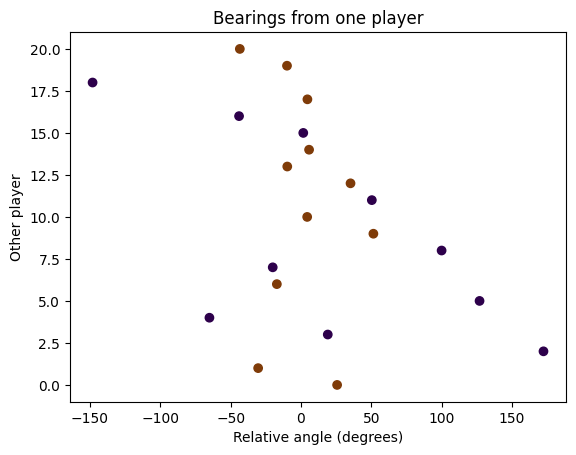

In [4]:
def relative_bearings(nodes,pid,sign):
    player=nodes[nodes.player_id.eq(pid)].iloc[0]
    others=nodes[~nodes.player_id.eq(pid)].copy()
    delta=sign*(others[['x','y']].to_numpy()-player[['x','y']].to_numpy(dtype=float))
    others['bearing']=np.arctan2(delta[:,1],delta[:,0]);others['same_team']=others.team_id.eq(player.team_id)
    return others
pid=snapshot[snapshot.team_id.eq(1802)].player_id.iloc[0];bearings=relative_bearings(snapshot,pid,-1)
display(bearings[['player_id','same_team','bearing']].head())
plt.scatter(np.degrees(bearings.bearing),np.arange(len(bearings)),c=bearings.same_team,cmap='PuOr');plt.xlabel('Relative angle (degrees)');plt.ylabel('Other player');plt.title('Bearings from one player');plt.show()

## 5. Build sector-membership indicators

A geometric field of view determines which players contribute to each heading bin.

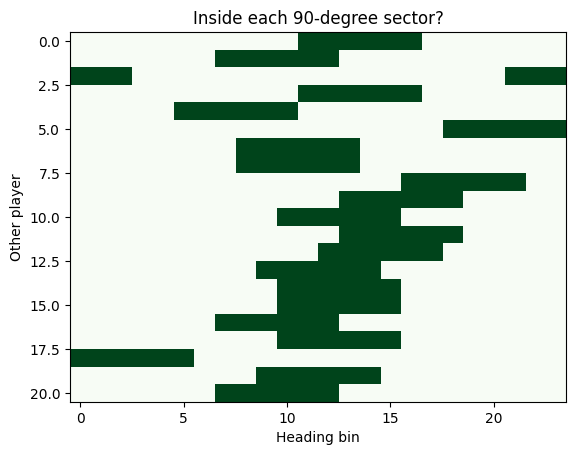

In [5]:
headings=np.linspace(-np.pi,np.pi,24,endpoint=False)
separation=np.angle(np.exp(1j*(bearings.bearing.to_numpy()[:,None]-headings)))
membership=np.abs(separation)<=np.pi/4+1e-12
plt.imshow(membership,aspect='auto',cmap='Greens');plt.xlabel('Heading bin');plt.ylabel('Other player');plt.title('Inside each 90-degree sector?');plt.show()

## 6. Sum teammate and opponent counts

Turn the membership matrix into feature channels, then manufacture one row per player.

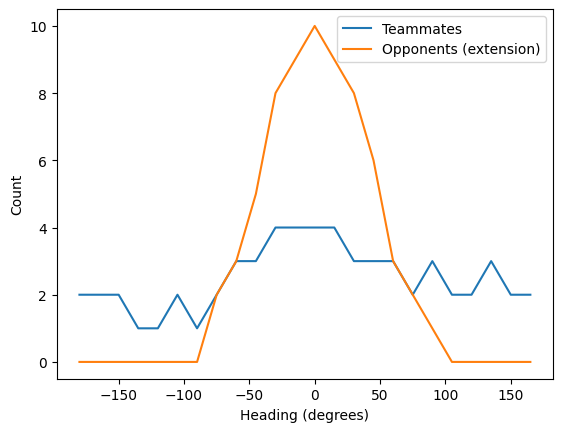

,player_id,metadata_role,mate_0,mate_1,mate_2,mate_3,mate_4,mate_5,mate_6,mate_7
0,11897,RB,1,1,0,0,0,0,0,0
1,287934,RDM,2,2,2,1,1,2,1,2
2,50982,LB,0,1,1,3,4,5,8,8
3,50999,GK,0,0,0,0,0,0,0,1
4,51002,LDM,5,4,4,2,3,3,3,3


In [6]:
def angular_counts(nodes,pid,attack_sign=1,bins=24,fov=90):
    p=nodes[nodes.player_id.eq(pid)].iloc[0]
    others=nodes[~nodes.player_id.eq(pid)]
    delta=attack_sign*(others[['x','y']].to_numpy()-p[['x','y']].to_numpy(dtype=float))
    angles=np.arctan2(delta[:,1],delta[:,0]);headings=np.linspace(-np.pi,np.pi,bins,endpoint=False)
    difference=np.angle(np.exp(1j*(angles[:,None]-headings)))
    inside=np.abs(difference)<=np.deg2rad(fov/2)+1e-12
    same=others.team_id.eq(p.team_id).to_numpy()
    return headings,inside[same].sum(axis=0),inside[~same].sum(axis=0)
angles,mates,opponents=angular_counts(snapshot,pid,attack_sign=-1)
plt.plot(np.degrees(angles),mates,label='Teammates');plt.plot(np.degrees(angles),opponents,label='Opponents (extension)');plt.xlabel('Heading (degrees)');plt.ylabel('Count');plt.legend();plt.show()
rows=[]
for _,p in snapshot.iterrows():
    _,m,o=angular_counts(snapshot,p.player_id,attack_sign=-1 if p.team_id==1802 else 1)
    rows.append(dict(player_id=p.player_id,metadata_role=role_labels[p.player_id],**{f'mate_{i}':v for i,v in enumerate(m)},**{f'opp_{i}':v for i,v in enumerate(o)}))
features=pd.DataFrame(rows);display(features.iloc[:5,:10])

### Spatial signatures for contrasting roles (slide 11)

Compare a fullback, a defensive midfielder and a forward from the **same real tracking frame**. At each of 24 attack-normalized headings, count teammates inside a 90° sector around the focal player. The three polar curves are the spatial signatures shown on the slide; the adjacent geometry panel explains one player's forward-facing sector.

We use **teammates only** for this comparison, following the slide. Opponent counts above are an additional feature channel. The focal player is excluded, and all ten teammates—including the goalkeeper—are eligible. Forward, left, back and right refer to attack-normalized pitch axes, not measured body or gaze direction. Sector membership ignores occlusion.

The role names come from match metadata and identify contrasting examples; they are **not predicted roles or reviewed frame-level ground truth**. Similar roles may have similar signatures across suitable samples, but one frame cannot establish classifier performance. The separate synthetic optimizer check follows this real-data visualization.

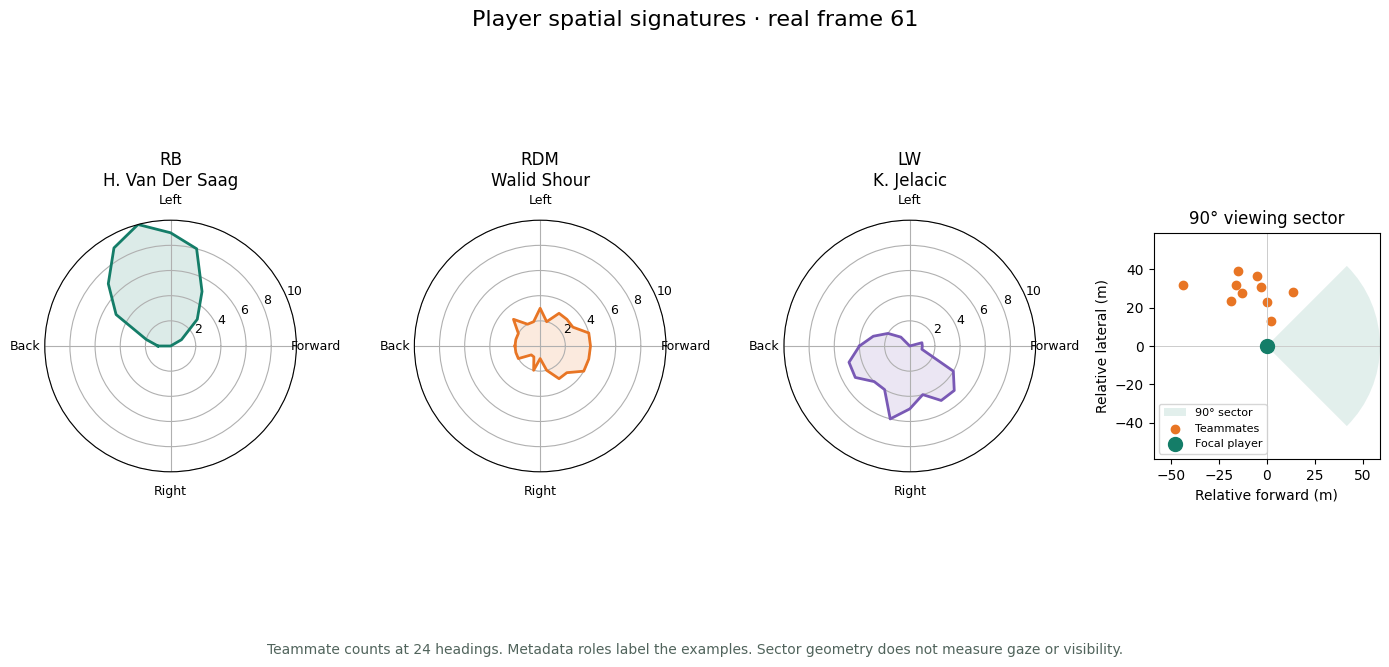

,,heading_bins,min_count,max_count
player_id,metadata_role,,,
287934,RDM,24,1,4
51043,RB,24,0,10
560986,LW,24,0,6


In [7]:
from matplotlib.patches import Wedge

player_lookup={str(p['id']):p for p in metadata['players']}
home=snapshot[snapshot.team_id.eq(1802)].copy()
home['role']=home.player_id.map(role_labels)
assert len(home)==11, 'Use a complete team snapshot for comparable counts.'
chosen_players=[]
for role_group in [['RB','LB'],['LDM','RDM','CDM'],['CF','LW','RW']]:
    candidates=home[home.role.isin(role_group)]
    assert len(candidates), f'No example for {role_group} in this frame'
    chosen_players.append(candidates.iloc[0])

fig=plt.figure(figsize=(14,7))
grid=fig.add_gridspec(1,4,width_ratios=[1,1,1,.9])
colors=['#147d68','#e87524','#7959b5']
signature_rows=[]
for j,player in enumerate(chosen_players):
    headings,mate_counts,_=angular_counts(snapshot,player.player_id,attack_sign=-1,bins=24,fov=90)
    closed_heading=np.r_[headings,headings[0]]
    closed_count=np.r_[mate_counts,mate_counts[0]]
    ax=fig.add_subplot(grid[0,j],projection='polar')
    ax.plot(closed_heading,closed_count,c=colors[j],lw=2)
    ax.fill(closed_heading,closed_count,color=colors[j],alpha=.15)
    ax.set(ylim=(0,10),title=f"{player.role}\n{player_lookup[player.player_id]['short_name']}")
    ax.set_xticks([0,np.pi/2,np.pi,3*np.pi/2],['Forward','Left','Back','Right'])
    ax.tick_params(labelsize=9)
    signature_rows.extend(dict(player_id=player.player_id,metadata_role=player.role,heading_degrees=float(h),teammate_count=int(c)) for h,c in zip(np.degrees(headings),mate_counts))
    # Relative geometry must be invariant to translating every player together.
    translated=snapshot.copy();translated[['x','y']]+=np.array([25.,-12.])
    assert np.array_equal(angular_counts(translated,player.player_id,-1)[1],mate_counts)
    assert np.all((mate_counts>=0)&(mate_counts<=10))

focal=chosen_players[0]
others=home[home.player_id.ne(focal.player_id)]
delta=-(others[['x','y']].to_numpy()-focal[['x','y']].to_numpy(dtype=float))
ax=fig.add_subplot(grid[0,3]);radius=float(np.linalg.norm(delta,axis=1).max()+5)
ax.add_patch(Wedge((0,0),radius,-45,45,facecolor='#147d68',alpha=.12,label='90° sector'))
ax.scatter(*delta.T,c='#e87524',label='Teammates')
ax.scatter(0,0,s=100,c='#147d68',label='Focal player',zorder=4)
ax.axhline(0,c='#ccc',lw=.7);ax.axvline(0,c='#ccc',lw=.7)
ax.set(xlim=(-radius,radius),ylim=(-radius,radius),aspect='equal',title='90° viewing sector',xlabel='Relative forward (m)',ylabel='Relative lateral (m)')
ax.legend(fontsize=8,loc='lower left')
fig.suptitle(f'Player spatial signatures · real frame {frame_id}',fontsize=16)
fig.text(.5,.06,'Teammate counts at 24 headings. Metadata roles label the examples. Sector geometry does not measure gaze or visibility.',ha='center',fontsize=10,color='#51645c')
fig.tight_layout(rect=(0,.1,1,.95));plt.show()
spatial_signatures=pd.DataFrame(signature_rows)
display(spatial_signatures.groupby(['player_id','metadata_role']).agg(heading_bins=('heading_degrees','size'),min_count=('teammate_count','min'),max_count=('teammate_count','max')))
assert len(spatial_signatures)==3*24


## 7. Inspect softmax before training

Convert illustrative class scores into a probability distribution. Training will use this same helper.

,score,probability
0,1.0,0.253716
1,2.0,0.689672
2,-0.5,0.056612


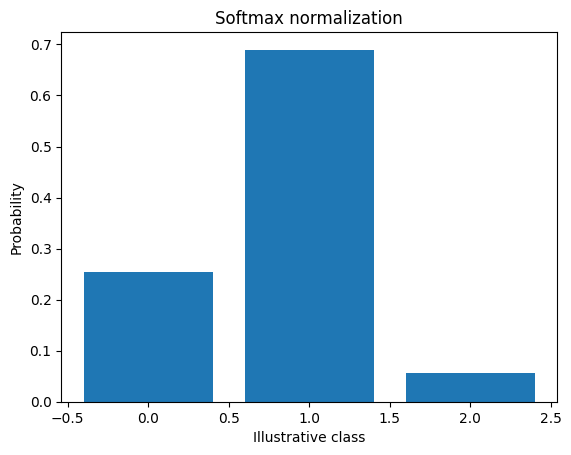

In [8]:
def softmax(z):
    z=z-z.max(axis=1,keepdims=True);p=np.exp(z);return p/p.sum(axis=1,keepdims=True)
scores=np.array([[1.,2.,-.5]]);p=softmax(scores);display(pd.DataFrame({'score':scores[0],'probability':p[0]}));assert np.isclose(p.sum(),1)
plt.bar(range(3),p[0]);plt.xlabel('Illustrative class');plt.ylabel('Probability');plt.title('Softmax normalization');plt.show()

## 8. Final output: verify the classifier optimizer

The original Pleuler approach used XGBoost. This transparent softmax classifier is trained on clearly labeled synthetic features to check its mechanics, not to claim real role accuracy.

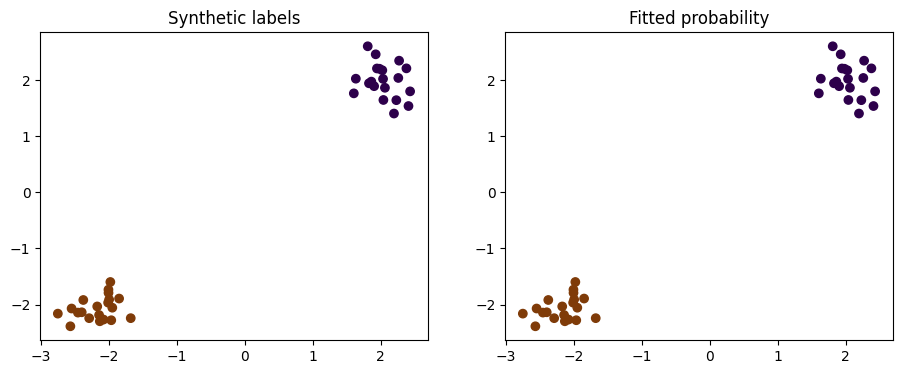

In [9]:
def train_roles(X,y,n_classes,steps=600,lr=.1):
    X=np.c_[np.ones(len(X)),np.asarray(X,float)];W=np.zeros((X.shape[1],n_classes))
    target=np.eye(n_classes)[np.asarray(y,int)]
    for _ in range(steps):W-=lr*X.T@(softmax(X@W)-target)/len(X)
    return W
rng=np.random.default_rng(7);toy_X=np.r_[rng.normal(-2,.3,(20,2)),rng.normal(2,.3,(20,2))];toy_y=np.repeat([0,1],20)
W=train_roles(toy_X,toy_y,2);probability=softmax(np.c_[np.ones(40),toy_X]@W);assert (probability.argmax(axis=1)==toy_y).all()
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].scatter(toy_X[:,0],toy_X[:,1],c=toy_y,cmap='PuOr');axs[0].set_title('Synthetic labels');axs[1].scatter(toy_X[:,0],toy_X[:,1],c=probability[:,1],cmap='PuOr',vmin=0,vmax=1);axs[1].set_title('Fitted probability');plt.show()

## Interpretation and limitations

Angular sectors model geometry, not measured gaze or occlusion. Opponent counts extend Pleuler’s teammate features. Metadata roles are weak labels during rotations. Credible training needs reviewed frame roles and held-out matches/players. [Pleuler](https://github.com/devinpleuler/research/blob/master/frame-by-frame-position.md).